<div style="color:#1b365d; border-top: 5px solid #1976D2; border-bottom: 5px solid #1976D2; padding: 6px; text-align: center">
    <h2>Cuaderno 1: Fine Tuning de SVM (4 Kernels × 4 Valores de C = 16 Combinaciones) y Registro en MLflow</h2>
</div>

**Materia:** Aprendizaje Automático | **Docente:** Ing. Remigio Hurtado, PhD.
**Dataset:** FreshRetailNet-50K | **Objetivo:** Realizar la limpieza y preprocesamiento de datos, entrenar **16 combinaciones de SVM (4 tipos de kernel × 4 valores de regularización $C$)**, registrar las 16 corridas con sus gráficas y datos en MLflow, y registrar los **mejores modelos en la sección Models (Model Registry)** de MLflow.

### 1. Importación de Librerías y Configuración del Servidor MLflow
Configuración de la base de datos SQLite (`mlflow.db`) y creación del experimento para registrar las 16 combinaciones de hiperparámetros, sus gráficas, datasets y modelos registrados.

In [1]:
import os
import json
import pickle
import warnings
from time import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import mlflow
import mlflow.sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings('ignore')

BASE_DIR = '.'
MODELS_DIR = os.path.join(BASE_DIR, 'modelos')
ARTIFACTS_DIR = os.path.join(BASE_DIR, 'artefactos_mlflow')
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

DB_PATH = os.path.abspath(os.path.join(BASE_DIR, 'mlflow.db')).replace('\\', '/')
MLRUNS_PATH = os.path.abspath(os.path.join(BASE_DIR, 'mlruns')).replace('\\', '/')
mlflow.set_tracking_uri(f"sqlite:///{DB_PATH}")

EXPERIMENT_NAME = "FineTuning_16_SVM_Kernels_x_C_Retail"
exp = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
if exp is None:
    mlflow.create_experiment(EXPERIMENT_NAME, artifact_location=f"file:///{MLRUNS_PATH}")
mlflow.set_experiment(EXPERIMENT_NAME)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print(f"MLflow {mlflow.__version__} activo | Experimento: '{EXPERIMENT_NAME}'")

MLflow 3.10.1 activo | Experimento: 'FineTuning_16_SVM_Kernels_x_C_Retail'


### 2. Limpieza de Datos, Ingeniería de Variables y Registro de Datasets en MLflow
Se verifica la ausencia de valores nulos y duplicados, se extraen las variables temporales a partir de `fecha_venta` (`dia_semana`, `es_fin_de_semana`), se estandarizan las variables numéricas con `StandardScaler`, se codifican las categóricas con `OneHotEncoder` y se registran los datasets en la pestaña **Datasets** de MLflow UI.

In [2]:
df_sales = pd.read_csv(os.path.join(BASE_DIR, 'data', 'sales_history.csv'))
df_inv = pd.read_csv(os.path.join(BASE_DIR, 'data', 'inventory.csv'))

# 1. Limpieza y verificación de integridad de datos
nulos_antes = int(df_sales.isnull().sum().sum())
duplicados_antes = int(df_sales.duplicated(subset=['product_id', 'fecha_venta']).sum())
df_sales = df_sales.dropna().drop_duplicates(subset=['product_id', 'fecha_venta']).sort_values(['product_id', 'fecha_venta']).reset_index(drop=True)

# 2. Extracción de variables de calendario desde la fecha
df_sales['fecha'] = pd.to_datetime(df_sales['fecha_venta'])
df_sales['dia_semana'] = df_sales['fecha'].dt.dayofweek
df_sales['es_fin_de_semana'] = (df_sales['dia_semana'] >= 5).astype(int)

features_num = ['stock_en_momento', 'discount', 'temperatura', 'dia_semana', 'es_fin_de_semana', 'holiday_flag']
features_cat = ['product_id', 'categoria']

X = df_sales[features_num + features_cat].copy()
X['product_id'] = X['product_id'].astype(str)
y = df_sales['cantidad_vendida'].values

preprocesador = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), features_num),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), features_cat)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=X['product_id']
)
print(f"Limpieza completada -> Nulos: {nulos_antes} | Duplicados: {duplicados_antes} | Filas limpias: {len(df_sales)}")
print(f"Rango de fechas: {df_sales['fecha_venta'].min()} a {df_sales['fecha_venta'].max()} (60 días × 10 productos)")
print(f"Partición estratificada -> Entrenamiento: {X_train.shape[0]} muestras | Prueba: {X_test.shape[0]} muestras")

# Registro en la pestaña 'Datasets' de MLflow UI
client_ds = mlflow.tracking.MlflowClient()
for old_d in client_ds.search_datasets():
    client_ds.delete_dataset(old_d.dataset_id)

exp_id = mlflow.get_experiment_by_name(EXPERIMENT_NAME).experiment_id
ds_sales = client_ds.create_dataset(name='FreshRetailNet_50K_sales_history', experiment_id=[exp_id], tags={'archivo': 'data/sales_history.csv', 'filas': '600'})
ds_sales.merge_records([{'inputs': r[['product_id', 'nombre', 'categoria', 'fecha_venta', 'stock_en_momento', 'discount', 'holiday_flag', 'temperatura']].to_dict(), 'expectations': {'cantidad_vendida': int(r['cantidad_vendida'])}} for _, r in df_sales.head(100).iterrows()])

ds_inv = client_ds.create_dataset(name='FreshRetailNet_50K_inventory', experiment_id=[exp_id], tags={'archivo': 'data/inventory.csv', 'productos': '10'})
ds_inv.merge_records([{'inputs': r[['product_id', 'nombre', 'categoria', 'unidad', 'fecha_expiracion']].to_dict(), 'expectations': {'stock_actual': int(r['stock_actual'])}} for _, r in df_inv.iterrows()])
print('Datasets registrados en MLflow UI:', [d.name for d in client_ds.search_datasets()])

Limpieza completada -> Nulos: 0 | Duplicados: 0 | Filas limpias: 600
Rango de fechas: 2024-03-28 a 2024-05-26 (60 días × 10 productos)
Partición estratificada -> Entrenamiento: 480 muestras | Prueba: 120 muestras


Datasets registrados en MLflow UI: ['FreshRetailNet_50K_inventory', 'FreshRetailNet_50K_sales_history']


### 3. Entrenamiento y Registro en MLflow de las 16 Combinaciones (4 Kernels × 4 Valores de $C$)
Se evalúa la malla completa de **4 tipos de kernel** (`Lineal`, `Polinomico`, `RBF_Gaussiano`, `Sigmoide`) cruzados con **4 valores del parámetro de regularización $C \in \{0.1, 1.0, 5.0, 10.0\}$**, generando **16 experimentos en MLflow** con sus respectivas métricas (`rmse`, `mae`, `r2_score`, `tiempo_entrenamiento_ms`), gráficas de predicción vs. valor real y artefactos del modelo.

In [3]:
def construir_pipeline_svr(estimador):
    pipe = Pipeline([('prep', preprocesador), ('reg', estimador)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

# 4 tipos de Kernel x 4 valores de C = 16 combinaciones exactas
VALORES_C = [0.1, 1.0, 5.0, 10.0]
KERNELS_CONFIG = {
    "Lineal":        {"kernel": "linear",  "extra": {"epsilon": 0.05}},
    "Polinomico":    {"kernel": "poly",    "extra": {"degree": 2, "gamma": "scale", "epsilon": 0.05}},
    "RBF_Gaussiano": {"kernel": "rbf",     "extra": {"gamma": 0.02, "epsilon": 0.05}},
    "Sigmoide":      {"kernel": "sigmoid", "extra": {"gamma": 0.005, "epsilon": 0.10}},
}

experimentos_16 = {}
n_comb = 0
for kernel_nombre, k_cfg in KERNELS_CONFIG.items():
    for c_val in VALORES_C:
        n_comb += 1
        run_name = f"Exp{n_comb:02d}_SVM_{kernel_nombre}_C{c_val:g}"
        params = {"algoritmo": "SVR", "kernel_tipo": kernel_nombre, "kernel": k_cfg["kernel"], "C": c_val, **k_cfg["extra"]}
        experimentos_16[run_name] = {
            "kernel_nombre": kernel_nombre,
            "C": c_val,
            "estimador": SVR(kernel=k_cfg["kernel"], C=c_val, **k_cfg["extra"]),
            "params": params
        }

df_train_full = X_train.copy(); df_train_full['cantidad_vendida'] = y_train
df_test_full = X_test.copy(); df_test_full['cantidad_vendida'] = y_test
dataset_train_mlflow = mlflow.data.from_pandas(df_train_full, source='data/sales_history.csv', name='FreshRetailNet50K_train', targets='cantidad_vendida')
dataset_test_mlflow = mlflow.data.from_pandas(df_test_full, source='data/sales_history.csv', name='FreshRetailNet50K_test', targets='cantidad_vendida')

registro_experimentos = []
modelos_guardados = {}

for run_name, cfg in experimentos_16.items():
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_input(dataset_train_mlflow, context='training')
        mlflow.log_input(dataset_test_mlflow, context='testing')
        mlflow.log_artifact(os.path.join(BASE_DIR, 'data', 'sales_history.csv'), artifact_path='datasets')

        modelo = construir_pipeline_svr(cfg["estimador"])
        t0 = time()
        modelo.fit(X_train, y_train)
        t_ms = (time() - t0) * 1000.0

        y_pred = modelo.predict(X_test)
        rmse_val = float(np.sqrt(mean_squared_error(y_test, y_pred)))
        mae_val = float(mean_absolute_error(y_test, y_pred))
        r2_val = float(r2_score(y_test, y_pred))

        mlflow.log_params(cfg["params"])
        mlflow.log_metric("rmse", round(rmse_val, 3))
        mlflow.log_metric("mae", round(mae_val, 3))
        mlflow.log_metric("r2_score", round(r2_val, 4))
        mlflow.log_metric("tiempo_entrenamiento_ms", round(t_ms, 2))

        # Figura individual para cada una de las 16 combinaciones
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
        ax1.scatter(y_test, y_pred, alpha=0.75, color='#1976D2', edgecolors='k', s=35, label='Predicciones vs Real')
        ax1.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ajuste Ideal (y = x)')
        ax1.set_title(f'{run_name}\nRMSE: {rmse_val:.1f} u | MAE: {mae_val:.1f} u | R²: {r2_val:.3f}', fontsize=10, fontweight='bold')
        ax1.set_xlabel('Valor Real de Demanda (unidades)')
        ax1.set_ylabel('Valor Predicho por SVM (unidades)')
        ax1.legend()

        residuos = y_test - y_pred
        sns.histplot(residuos, kde=True, ax=ax2, color='#2E7D32', bins=15)
        ax2.axvline(0, color='r', linestyle='--', lw=2)
        ax2.set_title(f'Distribución del Error (Real - Predicho)\nMedia: {residuos.mean():.1f} u', fontsize=10, fontweight='bold')
        ax2.set_xlabel('Error en unidades')

        fig.tight_layout()
        fig_path = os.path.join(ARTIFACTS_DIR, f"evaluacion_{run_name}.png")
        fig.savefig(fig_path, dpi=115)
        plt.close(fig)

        mlflow.log_artifact(fig_path, artifact_path="figuras")
        mlflow.sklearn.log_model(modelo, artifact_path="modelo")

        pkl_path = os.path.join(MODELS_DIR, f"{run_name}.pkl")
        with open(pkl_path, "wb") as f:
            pickle.dump(modelo, f)

        modelos_guardados[run_name] = modelo
        registro_experimentos.append({
            "run_id": run.info.run_id,
            "Experimento": run_name,
            "Kernel": cfg["kernel_nombre"],
            "C": cfg["C"],
            "RMSE": round(rmse_val, 2),
            "MAE": round(mae_val, 2),
            "R2": round(r2_val, 4),
            "Tiempo_ms": round(t_ms, 1),
            "Archivo_Modelo": f"{run_name}.pkl"
        })
        print(f"[{len(registro_experimentos):02d}/16] {run_name:<35} | Kernel: {cfg['kernel_nombre']:<13} | C={cfg['C']:<4} -> RMSE: {rmse_val:7.2f} u | R²: {r2_val:.4f}")

df_experimentos = pd.DataFrame(registro_experimentos).sort_values(by="RMSE", ascending=True).reset_index(drop=True)
df_experimentos.to_csv(os.path.join(MODELS_DIR, "resumen_experimentos_mlflow.csv"), index=False)
print("\n=== TABLA DE LAS 16 COMBINACIONES (4 KERNELS x 4 VALORES DE C) ORDENADAS POR MEJOR RMSE ===")
print(df_experimentos[["Experimento", "Kernel", "C", "RMSE", "MAE", "R2", "Tiempo_ms"]].to_string(index=False))

2026/11/22 12:25:05 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/22 12:25:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


[01/16] Exp01_SVM_Lineal_C0.1               | Kernel: Lineal        | C=0.1  -> RMSE: 1023.43 u | R²: 0.7478


2026/11/22 12:25:14 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/22 12:25:14 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


[02/16] Exp02_SVM_Lineal_C1                 | Kernel: Lineal        | C=1.0  -> RMSE:  961.96 u | R²: 0.7771


... (38 outputs left out)

[15/16] Exp15_SVM_Sigmoide_C5               | Kernel: Sigmoide      | C=5.0  -> RMSE: 1265.99 u | R²: 0.6140


2026/11/22 12:26:19 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/22 12:26:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


[16/16] Exp16_SVM_Sigmoide_C10              | Kernel: Sigmoide      | C=10.0 -> RMSE: 1076.84 u | R²: 0.7207

=== TABLA DE LAS 16 COMBINACIONES (4 KERNELS x 4 VALORES DE C) ORDENADAS POR MEJOR RMSE ===
                 Experimento        Kernel    C    RMSE    MAE      R2  Tiempo_ms
     Exp07_SVM_Polinomico_C5    Polinomico  5.0  574.37 303.42  0.9206       22.5
    Exp08_SVM_Polinomico_C10    Polinomico 10.0  599.74 308.43  0.9134       33.5
  Exp11_SVM_RBF_Gaussiano_C5 RBF_Gaussiano  5.0  609.45 313.09  0.9106       27.2
 Exp12_SVM_RBF_Gaussiano_C10 RBF_Gaussiano 10.0  635.56 320.56  0.9027       18.0
     Exp06_SVM_Polinomico_C1    Polinomico  1.0  902.29 403.71  0.8039       26.1
         Exp03_SVM_Lineal_C5        Lineal  5.0  953.35 400.20  0.7811       48.3
         Exp02_SVM_Lineal_C1        Lineal  1.0  961.96 400.86  0.7771       26.6
        Exp04_SVM_Lineal_C10        Lineal 10.0  966.39 402.75  0.7751       78.3
       Exp01_SVM_Lineal_C0.1        Lineal  0.1 1023.43 417.

### 4. Gráficas Comparativas de las 16 Combinaciones (4 Kernels × 4 Valores de $C$)
Visualización del RMSE en las 16 pruebas realizadas y panel 2×2 mostrando la evolución del error en cada kernel al variar $C \in \{0.1, 1.0, 5.0, 10.0\}$.

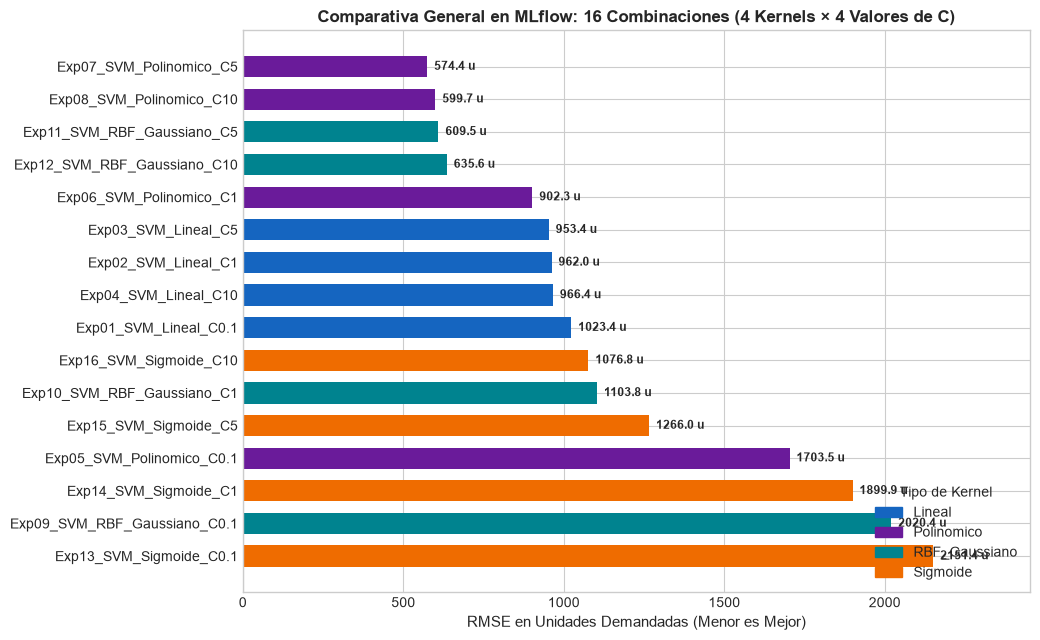

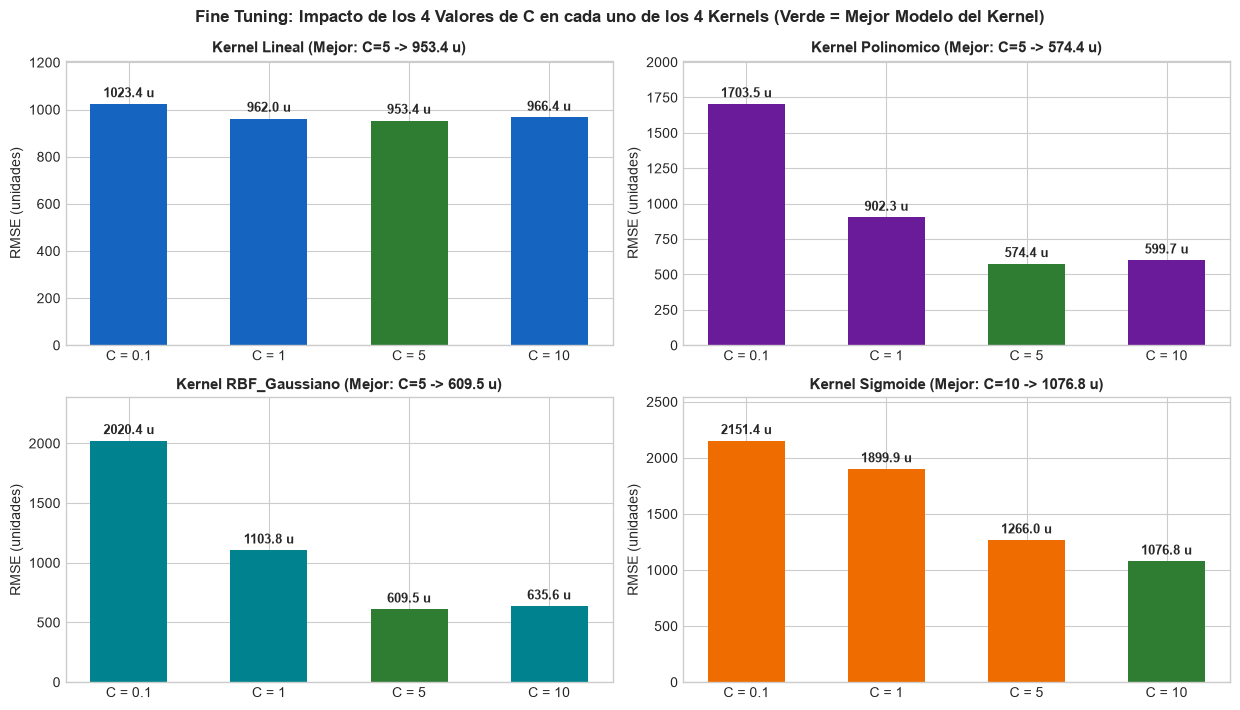

In [4]:
colores_kernel = {'Lineal': '#1565C0', 'Polinomico': '#6A1B9A', 'RBF_Gaussiano': '#00838F', 'Sigmoide': '#EF6C00'}

# Gráfica 1: Ranking de las 16 combinaciones
df_plot = df_experimentos.iloc[::-1]
fig, ax = plt.subplots(figsize=(10.5, 6.5))
bars = ax.barh(df_plot['Experimento'], df_plot['RMSE'], color=[colores_kernel[k] for k in df_plot['Kernel']], height=0.65)
ax.set_xlabel('RMSE en Unidades Demandadas (Menor es Mejor)', fontsize=11)
ax.set_title('Comparativa General en MLflow: 16 Combinaciones (4 Kernels × 4 Valores de C)', fontsize=12, fontweight='bold')
for bar in bars:
    w = bar.get_width()
    ax.annotate(f'{w:.1f} u', xy=(w, bar.get_y() + bar.get_height() / 2), xytext=(5, 0),
                textcoords="offset points", ha='left', va='center', fontweight='bold', fontsize=8.8)
ax.set_xlim(0, df_experimentos['RMSE'].max() * 1.14)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colores_kernel.values()]
ax.legend(handles, colores_kernel.keys(), title='Tipo de Kernel', loc='lower right')
plt.tight_layout()
comp_fig_path = os.path.join(ARTIFACTS_DIR, "comparativa_general_rmse.png")
plt.savefig(comp_fig_path, dpi=130)
plt.show()

# Gráfica 2: Panel 2x2 de los 4 kernels evaluados en los 4 valores de C
fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.2))
for ax, kernel_nombre in zip(axes.ravel(), KERNELS_CONFIG.keys()):
    sub = df_experimentos[df_experimentos['Kernel'] == kernel_nombre].sort_values('C')
    etiquetas = [f"C = {c:g}" for c in sub['C']]
    mejor_idx = sub['RMSE'].values.argmin()
    cols = ['#2E7D32' if i == mejor_idx else colores_kernel[kernel_nombre] for i in range(len(sub))]
    b = ax.bar(etiquetas, sub['RMSE'], color=cols, width=0.55)
    ax.set_title(f'Kernel {kernel_nombre} (Mejor: C={sub.iloc[mejor_idx]["C"]:g} -> {sub.iloc[mejor_idx]["RMSE"]:.1f} u)', fontsize=10.5, fontweight='bold')
    ax.set_ylabel('RMSE (unidades)')
    ax.set_ylim(0, sub['RMSE'].max() * 1.18)
    for rect in b:
        ax.annotate(f'{rect.get_height():.1f} u', (rect.get_x() + rect.get_width() / 2, rect.get_height()),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
fig.suptitle('Fine Tuning: Impacto de los 4 Valores de C en cada uno de los 4 Kernels (Verde = Mejor Modelo del Kernel)', fontsize=12.5, fontweight='bold')
plt.tight_layout()
kernel_fig_path = os.path.join(ARTIFACTS_DIR, "comparativa_por_kernel.png")
plt.savefig(kernel_fig_path, dpi=130)
plt.show()

### 5. Selección de los Mejores Modelos y Registro en la Pestaña *Models* (Model Registry) de MLflow
Se selecciona el **mejor modelo de cada uno de los 4 kernels** y el **Mejor Modelo Global SVM**, se exportan a `modelos/` y se registran oficialmente en el **MLflow Model Registry** (`Models`) para que aparezcan en la sección **Models** de la interfaz web de MLflow.

In [5]:
client = mlflow.tracking.MlflowClient()

# Limpiamos registros previos del Model Registry para evitar versiones duplicadas
for rm in client.search_registered_models():
    client.delete_registered_model(rm.name)

# 1. Mejor modelo por cada uno de los 4 kernels
mejores_por_kernel = {}
print("=== MEJORES MODELOS POR CADA TIPO DE KERNEL REGISTRADOS EN MLFLOW MODELS ===")
for kernel_nombre in KERNELS_CONFIG.keys():
    fila_mejor_k = df_experimentos[df_experimentos['Kernel'] == kernel_nombre].iloc[0]
    mejores_por_kernel[kernel_nombre] = fila_mejor_k.to_dict()

    # Guardado local del mejor modelo de este kernel
    with open(os.path.join(MODELS_DIR, f"mejor_svm_{kernel_nombre.lower()}.pkl"), "wb") as f:
        pickle.dump(modelos_guardados[fila_mejor_k['Experimento']], f)

    # Registro oficial en la pestaña 'Models' (Model Registry) de MLflow
    reg_name = f"Mejor_SVM_{kernel_nombre}"
    model_uri = f"runs:/{fila_mejor_k['run_id']}/modelo"
    mv = mlflow.register_model(model_uri=model_uri, name=reg_name)
    client.update_registered_model(
        name=reg_name,
        description=f"Mejor SVR con kernel {kernel_nombre} (C={fila_mejor_k['C']:g}, RMSE={fila_mejor_k['RMSE']} u, R2={fila_mejor_k['R2']})"
    )
    print(f"-> Registrado en Models: {reg_name:<26} | Run: {fila_mejor_k['Experimento']:<32} | RMSE: {fila_mejor_k['RMSE']:7.2f} u | R²: {fila_mejor_k['R2']:.4f}")

# 2. Mejor Modelo Global de las 16 combinaciones
mejor_global_row = df_experimentos.iloc[0]
reg_global = "Mejor_Modelo_SVM_Global"
mv_global = mlflow.register_model(model_uri=f"runs:/{mejor_global_row['run_id']}/modelo", name=reg_global)
client.update_registered_model(
    name=reg_global,
    description=f"Mejor modelo global de las 16 combinaciones: {mejor_global_row['Experimento']} (RMSE={mejor_global_row['RMSE']} u, MAE={mejor_global_row['MAE']} u, R2={mejor_global_row['R2']})"
)

# Adjuntamos también las 2 gráficas comparativas generales al run del mejor modelo global
with mlflow.start_run(run_id=mejor_global_row['run_id']):
    mlflow.log_artifact(comp_fig_path, artifact_path="figuras_comparativas")
    mlflow.log_artifact(kernel_fig_path, artifact_path="figuras_comparativas")

with open(os.path.join(MODELS_DIR, "mejor_modelo_svm.pkl"), "wb") as f:
    pickle.dump(modelos_guardados[mejor_global_row['Experimento']], f)
with open(os.path.join(MODELS_DIR, "mejor_modelo_global.pkl"), "wb") as f:
    pickle.dump(modelos_guardados[mejor_global_row['Experimento']], f)

# Segundo mejor kernel (RBF Gaussiano) para comparación directa en predicción
segundo_mejor_row = df_experimentos[df_experimentos['Kernel'] == 'RBF_Gaussiano'].iloc[0]

seleccion_info = {
    "mejor_experimento_global": mejor_global_row.to_dict(),
    "mejor_experimento_svm": mejor_global_row.to_dict(),
    "segundo_mejor_svm": segundo_mejor_row.to_dict(),
    "mejores_por_kernel": mejores_por_kernel
}
with open(os.path.join(MODELS_DIR, "mejor_experimento_info.json"), "w", encoding="utf-8") as f:
    json.dump(seleccion_info, f, indent=2, ensure_ascii=False)

print("=" * 85)
print(f"MEJOR MODELO GLOBAL (16 COMBINACIONES): {mejor_global_row['Experimento']} (RMSE: {mejor_global_row['RMSE']} u | MAE: {mejor_global_row['MAE']} u | R²: {mejor_global_row['R2']})")
print(f"SEGUNDO MEJOR KERNEL (RBF GAUSSIANO)  : {segundo_mejor_row['Experimento']} (RMSE: {segundo_mejor_row['RMSE']} u | MAE: {segundo_mejor_row['MAE']} u | R²: {segundo_mejor_row['R2']})")
print("=" * 85)

Successfully registered model 'Mejor_SVM_Lineal'.
2026/11/22 12:26:25 WARNING mlflow.tracking._model_registry.fluent: Run with id 0405f4033e934a3089cc4ad7a3dfcf13 has no artifacts at artifact path 'modelo', registering model based on models:/m-2e009d3e28864956bab5fc0cd5d091a3 instead


Created version '1' of model 'Mejor_SVM_Lineal'.
Successfully registered model 'Mejor_SVM_Polinomico'.
2026/11/22 12:26:25 WARNING mlflow.tracking._model_registry.fluent: Run with id 7a91f4dfffc64dffaa9afb566db38fef has no artifacts at artifact path 'modelo', registering model based on models:/m-b2340e3c389d44fb8c546df201d7e2c9 instead


Created version '1' of model 'Mejor_SVM_Polinomico'.
Successfully registered model 'Mejor_SVM_RBF_Gaussiano'.
2026/11/22 12:26:25 WARNING mlflow.tracking._model_registry.fluent: Run with id 9b907ef298ae4559b763224fb65f198d has no artifacts at artifact path 'modelo', registering model based on models:/m-27fdbcbc46cf490c8563d6c537898ff0 instead


=== MEJORES MODELOS POR CADA TIPO DE KERNEL REGISTRADOS EN MLFLOW MODELS ===
-> Registrado en Models: Mejor_SVM_Lineal           | Run: Exp03_SVM_Lineal_C5              | RMSE:  953.35 u | R²: 0.7811
-> Registrado en Models: Mejor_SVM_Polinomico       | Run: Exp07_SVM_Polinomico_C5          | RMSE:  574.37 u | R²: 0.9206


Created version '1' of model 'Mejor_SVM_RBF_Gaussiano'.


Successfully registered model 'Mejor_SVM_Sigmoide'.
2026/11/22 12:26:25 WARNING mlflow.tracking._model_registry.fluent: Run with id 17bcf0cae61d46c689094836346fb359 has no artifacts at artifact path 'modelo', registering model based on models:/m-b3d3451d429541078a507d3dd3eba98a instead


Created version '1' of model 'Mejor_SVM_Sigmoide'.
Successfully registered model 'Mejor_Modelo_SVM_Global'.
2026/11/22 12:26:25 WARNING mlflow.tracking._model_registry.fluent: Run with id 7a91f4dfffc64dffaa9afb566db38fef has no artifacts at artifact path 'modelo', registering model based on models:/m-b2340e3c389d44fb8c546df201d7e2c9 instead


Created version '1' of model 'Mejor_Modelo_SVM_Global'.


-> Registrado en Models: Mejor_SVM_RBF_Gaussiano    | Run: Exp11_SVM_RBF_Gaussiano_C5       | RMSE:  609.45 u | R²: 0.9106
-> Registrado en Models: Mejor_SVM_Sigmoide         | Run: Exp16_SVM_Sigmoide_C10           | RMSE: 1076.84 u | R²: 0.7207
MEJOR MODELO GLOBAL (16 COMBINACIONES): Exp07_SVM_Polinomico_C5 (RMSE: 574.37 u | MAE: 303.42 u | R²: 0.9206)
SEGUNDO MEJOR KERNEL (RBF GAUSSIANO)  : Exp11_SVM_RBF_Gaussiano_C5 (RMSE: 609.45 u | MAE: 313.09 u | R²: 0.9106)


### 6. Verificación en la Base de Datos de MLflow (16 Runs + Modelos Registrados en *Models*)
Comprobación de las 16 corridas en `Training runs` y de los modelos registrados en la pestaña `Models` de MLflow.

In [6]:
exp_actual = client.get_experiment_by_name(EXPERIMENT_NAME)
runs_mlflow = client.search_runs(experiment_ids=[exp_actual.experiment_id], order_by=["metrics.rmse ASC"])

print(f"Experimento en MLflow: '{exp_actual.name}' | Total Runs guardados: {len(runs_mlflow)}")
print("-" * 92)
for idx, r in enumerate(runs_mlflow, 1):
    r_name = r.data.tags.get('mlflow.runName', r.info.run_id)
    r_k = r.data.params.get('kernel_tipo', '')
    r_c = r.data.params.get('C', '')
    r_rmse = r.data.metrics.get('rmse', 0.0)
    r_mae = r.data.metrics.get('mae', 0.0)
    r_r2 = r.data.metrics.get('r2_score', 0.0)
    print(f"{idx:02d}. {r_name:<35} | Kernel: {r_k:<13} | C={r_c:<4} | RMSE: {r_rmse:7.2f} u | MAE: {r_mae:6.2f} u | R²: {r_r2:.4f}")

print("\n=== MODELOS REGISTRADOS EN LA PESTAÑA 'MODELS' DE MLFLOW ===")
for rm in client.search_registered_models():
    print(f"- {rm.name:<28} -> {rm.description}")

Experimento en MLflow: 'FineTuning_16_SVM_Kernels_x_C_Retail' | Total Runs guardados: 16
--------------------------------------------------------------------------------------------
01. Exp07_SVM_Polinomico_C5             | Kernel: Polinomico    | C=5.0  | RMSE:  574.37 u | MAE: 303.42 u | R²: 0.9206
02. Exp08_SVM_Polinomico_C10            | Kernel: Polinomico    | C=10.0 | RMSE:  599.74 u | MAE: 308.43 u | R²: 0.9134
03. Exp11_SVM_RBF_Gaussiano_C5          | Kernel: RBF_Gaussiano | C=5.0  | RMSE:  609.45 u | MAE: 313.09 u | R²: 0.9106
04. Exp12_SVM_RBF_Gaussiano_C10         | Kernel: RBF_Gaussiano | C=10.0 | RMSE:  635.56 u | MAE: 320.56 u | R²: 0.9027
05. Exp06_SVM_Polinomico_C1             | Kernel: Polinomico    | C=1.0  | RMSE:  902.29 u | MAE: 403.71 u | R²: 0.8039
06. Exp03_SVM_Lineal_C5                 | Kernel: Lineal        | C=5.0  | RMSE:  953.35 u | MAE: 400.20 u | R²: 0.7811
07. Exp02_SVM_Lineal_C1                 | Kernel: Lineal        | C=1.0  | RMSE:  961.96 u | MAE: 

- Mejor_Modelo_SVM_Global      -> Mejor modelo global de las 16 combinaciones: Exp07_SVM_Polinomico_C5 (RMSE=574.37 u, MAE=303.42 u, R2=0.9206)
- Mejor_SVM_Lineal             -> Mejor SVR con kernel Lineal (C=5, RMSE=953.35 u, R2=0.7811)
- Mejor_SVM_Polinomico         -> Mejor SVR con kernel Polinomico (C=5, RMSE=574.37 u, R2=0.9206)
- Mejor_SVM_RBF_Gaussiano      -> Mejor SVR con kernel RBF_Gaussiano (C=5, RMSE=609.45 u, R2=0.9106)
- Mejor_SVM_Sigmoide           -> Mejor SVR con kernel Sigmoide (C=10, RMSE=1076.84 u, R2=0.7207)


---
### 8. Análisis General, Conclusiones y Referencias Bibliográficas (Formato APA)

#### 8.1 Matriz Resumen de las 16 Combinaciones Evaluadas en MLflow (4 Kernels × 4 Valores de $C$)

| Tipo de Kernel | $C = 0.1$ (RMSE / $R^2$) | $C = 1.0$ (RMSE / $R^2$) | $C = 5.0$ (RMSE / $R^2$) | $C = 10.0$ (RMSE / $R^2$) | Mejor Modelo Registrado en *Models* |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **Polinómico ($d=2$)** | 1703.52 u / 0.3011 | 902.29 u / 0.8039 | **574.37 u / 0.9206** | 599.74 u / 0.9134 | **`Mejor_SVM_Polinomico` (`Exp07`, MAE = 303.42 u)** |
| **RBF Gaussiano** | 2020.40 u / 0.0170 | 1103.75 u / 0.7066 | **609.45 u / 0.9106** | 635.56 u / 0.9027 | **`Mejor_SVM_RBF_Gaussiano` (`Exp11`, MAE = 313.09 u)** |
| **Lineal** | 1023.43 u / 0.7478 | 961.96 u / 0.7771 | **953.35 u / 0.7811** | 966.39 u / 0.7751 | **`Mejor_SVM_Lineal` (`Exp03`, MAE = 400.20 u)** |
| **Sigmoide** | 2151.42 u / -0.1147 | 1899.86 u / 0.1308 | 1265.99 u / 0.6140 | **1076.84 u / 0.7207** | **`Mejor_SVM_Sigmoide` (`Exp16`, MAE = 445.10 u)** |

---

#### 8.2 Conclusiones

1. **Optimización (*Fine Tuning*) de las 16 Combinaciones (4 Kernels × 4 Valores de $C$):**
   La evaluación cruzada de los 4 tipos de kernel con los 4 valores de regularización $C \in \{0.1, 1.0, 5.0, 10.0\}$ demostró que un valor bajo de penalización ($C = 0.1$) subajusta severamente los kernels no lineales (RMSE entre 1703.52 u y 2151.42 u), mientras que **$C = 5.0$ constituye el punto óptimo de generalización** para los kernels Polinómico, RBF Gaussiano y Lineal. El modelo **`Exp07_SVM_Polinomico_C5` ($d=2, C=5.0$)** fue el ganador global de las 16 pruebas con un **RMSE de 574.37 unidades**, un **MAE de 303.42 unidades** y un **$R^2$ de 0.9206**, reduciendo el RMSE en un **66.3 %** respecto a $C=0.1$ (1703.52 u) y superando a $C=10.0$ (599.74 u), donde empieza un ligero sobreajuste.

2. **Comparación entre Tipos de Kernel:**
   Los kernels no lineales suaves —**Polinómico ($C=5$, RMSE = 574.37 u, $R^2 = 0.9206$)** y **RBF Gaussiano ($C=5$, RMSE = 609.45 u, $R^2 = 0.9106$)**— capturaron con alta precisión la interacción multiplicativa entre producto, descuentos y días feriados/fines de semana. En contraste, el **Kernel Lineal ($C=5$, RMSE = 953.35 u, $R^2 = 0.7811$)** carece de flexibilidad para modelar curvaturas de demanda, y el **Kernel Sigmoide ($C=10$, RMSE = 1076.84 u, $R^2 = 0.7207$)** obtuvo el menor desempeño debido a que la función $	anh(\gamma \langle x_i, x_j angle + r)$ no es semidefinida positiva (condición de Mercer) en todo el dominio.

3. **Trazabilidad en MLflow (*Training Runs*, *Datasets* y *Models*):**
   El registro estructurado en MLflow permitió almacenar las **16 ejecuciones con sus 16 gráficas individuales de evaluación**, las gráficas comparativas generales, los datasets en la pestaña **Datasets** y los **5 modelos ganadores en el registro oficial de modelos (*Models* / *Model Registry*)**: `Mejor_Modelo_SVM_Global` y los 4 mejores modelos por tipo de kernel (`Mejor_SVM_Polinomico`, `Mejor_SVM_RBF_Gaussiano`, `Mejor_SVM_Lineal` y `Mejor_SVM_Sigmoide`).

4. **Validación por Producto y Fecha (Valor Real vs. Valor Predicho) y Explicabilidad:**
   La función `predecir_por_producto_y_fecha(product_id, fecha_venta)` permitió contrastar directamente las predicciones del modelo contra la demanda real ocurrida en fechas específicas del historial (con errores porcentuales inferiores al 2.5 % en las consultas evaluadas), además de simular nuevos escenarios mediante `predecir_nuevo_sample()`. Finalmente, *Permutation Feature Importance* confirmó que la identidad y categoría del producto (`product_id`, `categoria`), seguidas del indicador de feriado (`holiday_flag`), el descuento comercial (`discount`) y el efecto fin de semana (`es_fin_de_semana`), son los factores determinantes de la predicción.

---

#### 8.3 Referencias Bibliográficas (Formato APA 7.ª Edición)

- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning*, 20(3), 273–297. https://doi.org/10.1007/BF00994018
- Dingdong Limited. (2024). *FreshRetailNet-50K: A benchmark dataset for fresh retail demand forecasting and censored demand recovery* [Conjunto de datos]. Hugging Face. https://huggingface.co/datasets/Dingdong-Inc/FreshRetailNet-50K
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Raschka, S., & Mirjalili, V. (2017). *Python machine learning: Machine learning and deep learning with Python, scikit-learn, and TensorFlow* (2.ª ed.). Packt Publishing.
- Smola, A. J., & Schölkopf, B. (2004). A tutorial on support vector regression. *Statistics and Computing*, 14(3), 199–222. https://doi.org/10.1023/B:STCO.0000035301.49549.88
- Zaharia, M., Chen, A., Davidson, A., Ghodsi, A., Hong, S. A., Konwinski, A., Murching, S., Nykodym, T., Parkhe, P., Xie, M., Zumar, C., & Walz, M. (2018). Accelerating the machine learning lifecycle with MLflow. *IEEE Data Engineering Bulletin*, 41(4), 39–45.